# 06-1 — Improvement : render new training attacks with everyday words (Kaggle)

**Why:** notebook 04 showed that DP's residual vulnerability grows with how strongly a word fools plain CLIP
(slope ≈ 0.45 on Pets and Caltech), while the authors train only on ImageNet-100 names, which are weak attacks
(plain CLIP fooled ≈ 18%). writes **everyday words** on half of the training images.

**What this notebook makes** (single pass over the 130,000 training images, rendering in parallel workers):
- `vocab.json`: 200 everyday training words + the held-out rest (never used in training);
- `train_attacks_vocab.pt`: two attacked versions per image with the **same** font, colour, size and position:
  `ctrl` (a wrong ImageNet-100 name, the authors' rule) and `vocab` (50%: an everyday word; else the same as `ctrl`).

**Before running (right panel):** GPU T4 · Internet On · *Add Input → Datasets:* `ambityga/imagenet100`.
Then **Save Version → Save & Run All** (runs in the background; the outputs are kept with the version).
**After it finishes:** from the version's *Output* tab download `vocab.json` and `train_attacks_vocab.pt` (~270 MB)
and upload both to `MyDrive/dp_project/cache_train/`.

In [1]:
# 1) Paths
import glob, os, sys, subprocess, json
W = "/kaggle/working"; BASE = "/tmp/work"; OUT = f"{W}/cache"
os.makedirs(BASE, exist_ok=True); os.makedirs(OUT, exist_ok=True)
SRC = os.path.dirname(glob.glob("/kaggle/input/**/Labels.json", recursive=True)[0])
print("ImageNet-100:", SRC, sorted(os.listdir(SRC)))
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader
print("CPU workers:", os.cpu_count())

ImageNet-100: /kaggle/input/datasets/ambityga/imagenet100 ['Labels.json', 'train.X1', 'train.X2', 'train.X3', 'train.X4', 'val.X']
Tesla T4, 15360 MiB
Tesla T4, 15360 MiB
CPU workers: 4


In [2]:
# 2)
# Dependencies, authors' code pinned to 50d7887, the two compatibility patches (same as every notebook)
!pip -q install ftfy regex git+https://github.com/openai/CLIP.git
import pathlib
os.chdir(BASE)
if not os.path.isdir("Defense-Prefix"):
    subprocess.run("git clone -q https://github.com/azuma164/Defense-Prefix.git", shell=True, check=True)
os.chdir(f"{BASE}/Defense-Prefix")
subprocess.run("git checkout -q 50d7887", shell=True, check=True)
p = pathlib.Path("datasets/utils/make_dataset_train.py"); s = p.read_text()
if "_textsize" not in s:
    helper = "\ndef _textsize(draw, text, font):\n    # Replacement for ImageDraw.textsize (removed in Pillow 10).\n    l, t, r, b = draw.multiline_textbbox((0, 0), text, font=font)\n    return r, b\n"
    s = s.replace("random.seed(300)", "random.seed(300)\n" + helper, 1).replace("imagedraw.textsize(text, font=font)", "_textsize(imagedraw, text, font)")
    p.write_text(s)
e = pathlib.Path("eval.py"); s = e.read_text()
e.write_text(s.replace("torch.load(args.tokens_path)", "torch.load(args.tokens_path, map_location=device, weights_only=False)"))
os.makedirs("data", exist_ok=True)
import torch, torchvision, PIL
print(subprocess.run("git rev-parse HEAD && git diff --stat", shell=True, capture_output=True, text=True).stdout)
print("python", sys.version.split()[0], "| torch", torch.__version__, "| torchvision", torchvision.__version__, "| Pillow", PIL.__version__)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
50d7887017b295e76b15e56c137ab47e68264448
 datasets/utils/make_dataset_train.py | 10 ++++++++--
 eval.py                              |  2 +-
 2 files changed, 9 insertions(+), 3 deletions(-)

python 3.13.16 | torch 2.11.0+cu130 | torchvision 0.26.0+cu130 | Pillow 13.0.0


In [3]:
%%writefile data/test_set_class_names.json
{
"pets": [
"Abyssinian",
"Bengal",
"Birman",
"Bombay",
"British Shorthair",
"Egyptian Mau",
"Maine Coon",
"Persian",
"Ragdoll",
"Russian Blue",
"Siamese",
"Sphynx",
"american bulldog",
"american pit bull terrier",
"basset hound",
"beagle",
"boxer",
"chihuahua",
"english cocker spaniel",
"english setter",
"german shorthaired",
"great pyrenees",
"havanese",
"japanese chin",
"keeshond",
"leonberger",
"miniature pinscher",
"newfoundland",
"pomeranian",
"pug",
"saint bernard",
"samoyed",
"scottish terrier",
"shiba inu",
"staffordshire bull terrier",
"wheaten terrier",
"yorkshire terrier"
],
"caltech": [
"accordion",
"airplane",
"anchor",
"ant",
"background",
"barrel",
"bass",
"beaver",
"binocular",
"body of a cougar cat",
"bonsai",
"brain",
"brontosaurus",
"buddha",
"butterfly",
"camera",
"cannon",
"ceiling fan",
"cellphone",
"centered face",
"chair",
"chandelier",
"crab",
"crayfish",
"crocodile",
"cup",
"dalmatian",
"dollar bill",
"dolphin",
"dragonfly",
"electric guitar",
"elephant",
"emu",
"euphonium",
"ewer",
"face of a cougar cat",
"ferry",
"flamingo",
"garfield",
"gerenuk",
"gramophone",
"grand piano",
"hawksbill",
"head of a crocodile",
"head of a flamingo",
"headphone",
"hedgehog",
"helicopter",
"ibis",
"inline skate",
"joshua tree",
"kangaroo",
"ketch",
"lamp",
"laptop",
"leopard",
"llama",
"lobster",
"lotus",
"mandolin",
"mayfly",
"menorah",
"metronome",
"minaret",
"motorbike",
"nautilus",
"octopus",
"off-center face",
"okapi",
"pagoda",
"panda",
"pigeon",
"pizza",
"platypus",
"pyramid",
"revolver",
"rhino",
"rooster",
"saxophone",
"schooner",
"scissors",
"scorpion",
"sea horse",
"side of a car",
"snoopy (cartoon beagle)",
"soccer ball",
"stapler",
"starfish",
"stegosaurus",
"stop sign",
"strawberry",
"sunflower",
"tick",
"trilobite",
"umbrella",
"watch",
"water lilly",
"wheelchair",
"wild cat",
"windsor chair",
"wrench",
"yin and yang symbol"
],
"flowers": [
"air plant",
"alpine sea holly",
"anthurium",
"artichoke",
"azalea",
"balloon flower",
"barbeton daisy",
"bearded iris",
"bee balm",
"bird of paradise",
"bishop of llandaff",
"black-eyed susan",
"blackberry lily",
"blanket flower",
"bolero deep blue",
"bougainvillea",
"bromelia",
"buttercup",
"californian poppy",
"camellia",
"canna lily",
"canterbury bells",
"cape flower",
"carnation",
"cautleya spicata",
"clematis",
"colt's foot",
"columbine",
"common dandelion",
"corn poppy",
"cyclamen",
"daffodil",
"desert-rose",
"english marigold",
"fire lily",
"foxglove",
"frangipani",
"fritillary",
"garden phlox",
"gaura",
"gazania",
"geranium",
"giant white arum lily",
"globe flower",
"globe thistle",
"grape hyacinth",
"great masterwort",
"hard-leaved pocket orchid",
"hibiscus",
"hippeastrum",
"japanese anemone",
"king protea",
"lenten rose",
"lotus",
"love in the mist",
"magnolia",
"mallow",
"marigold",
"mexican aster",
"mexican petunia",
"monkshood",
"moon orchid",
"morning glory",
"orange dahlia",
"osteospermum",
"oxeye daisy",
"passion flower",
"pelargonium",
"peruvian lily",
"petunia",
"pincushion flower",
"pink and yellow dahlia",
"pink primrose",
"poinsettia",
"primula",
"prince of wales feathers",
"purple coneflower",
"red ginger",
"rose",
"ruby-lipped cattleya",
"siam tulip",
"silverbush",
"snapdragon",
"spear thistle",
"spring crocus",
"stemless gentian",
"sunflower",
"sweet pea",
"sweet william",
"sword lily",
"thorn apple",
"tiger lily",
"toad lily",
"tree mallow",
"tree poppy",
"trumpet creeper",
"wallflower",
"water lily",
"watercress",
"wild pansy",
"windflower",
"yellow iris"
],
"food": [
"apple pie",
"baby back ribs",
"baklava",
"beef carpaccio",
"beef tartare",
"beet salad",
"beignets",
"bibimbap",
"bread pudding",
"breakfast burrito",
"bruschetta",
"caesar salad",
"cannoli",
"caprese salad",
"carrot cake",
"ceviche",
"cheese plate",
"cheesecake",
"chicken curry",
"chicken quesadilla",
"chicken wings",
"chocolate cake",
"chocolate mousse",
"churros",
"clam chowder",
"club sandwich",
"crab cakes",
"creme brulee",
"croque madame",
"cup cakes",
"deviled eggs",
"donuts",
"dumplings",
"edamame",
"eggs benedict",
"escargots",
"falafel",
"filet mignon",
"fish and chips",
"foie gras",
"french fries",
"french onion soup",
"french toast",
"fried calamari",
"fried rice",
"frozen yogurt",
"garlic bread",
"gnocchi",
"greek salad",
"grilled cheese sandwich",
"grilled salmon",
"guacamole",
"gyoza",
"hamburger",
"hot and sour soup",
"hot dog",
"huevos rancheros",
"hummus",
"ice cream",
"lasagna",
"lobster bisque",
"lobster roll sandwich",
"macaroni and cheese",
"macarons",
"miso soup",
"mussels",
"nachos",
"omelette",
"onion rings",
"oysters",
"pad thai",
"paella",
"pancakes",
"panna cotta",
"peking duck",
"pho",
"pizza",
"pork chop",
"poutine",
"prime rib",
"pulled pork sandwich",
"ramen",
"ravioli",
"red velvet cake",
"risotto",
"samosa",
"sashimi",
"scallops",
"seaweed salad",
"shrimp and grits",
"spaghetti bolognese",
"spaghetti carbonara",
"spring rolls",
"steak",
"strawberry shortcake",
"sushi",
"tacos",
"takoyaki",
"tiramisu",
"tuna tartare",
"waffles"
],
"aircraft": [
"707-320",
"727-200",
"737-200",
"737-300",
"737-400",
"737-500",
"737-600",
"737-700",
"737-800",
"737-900",
"747-100",
"747-200",
"747-300",
"747-400",
"757-200",
"757-300",
"767-200",
"767-300",
"767-400",
"777-200",
"777-300",
"A300B4",
"A310",
"A318",
"A319",
"A320",
"A321",
"A330-200",
"A330-300",
"A340-200",
"A340-300",
"A340-500",
"A340-600",
"A380",
"ATR-42",
"ATR-72",
"An-12",
"BAE 146-200",
"BAE 146-300",
"BAE-125",
"Beechcraft 1900",
"Boeing 717",
"C-130",
"C-47",
"CRJ-200",
"CRJ-700",
"CRJ-900",
"Cessna 172",
"Cessna 208",
"Cessna 525",
"Cessna 560",
"Challenger 600",
"DC-10",
"DC-3",
"DC-6",
"DC-8",
"DC-9-30",
"DH-82",
"DHC-1",
"DHC-6",
"DHC-8-100",
"DHC-8-300",
"DR-400",
"Dornier 328",
"E-170",
"E-190",
"E-195",
"EMB-120",
"ERJ 135",
"ERJ 145",
"Embraer Legacy 600",
"Eurofighter Typhoon",
"F-16A/B",
"F/A-18",
"Falcon 2000",
"Falcon 900",
"Fokker 100",
"Fokker 50",
"Fokker 70",
"Global Express",
"Gulfstream IV",
"Gulfstream V",
"Hawk T1",
"Il-76",
"L-1011",
"MD-11",
"MD-80",
"MD-87",
"MD-90",
"Metroliner",
"Model B200",
"PA-28",
"SR-20",
"Saab 2000",
"Saab 340",
"Spitfire",
"Tornado",
"Tu-134",
"Tu-154",
"Yak-42"
],
"dtd": [
"banded",
"blotchy",
"braided",
"bubbly",
"bumpy",
"chequered",
"cobwebbed",
"cracked",
"crosshatched",
"crystalline",
"dotted",
"fibrous",
"flecked",
"freckled",
"frilly",
"gauzy",
"grid",
"grooved",
"honeycombed",
"interlaced",
"knitted",
"lacelike",
"lined",
"marbled",
"matted",
"meshed",
"paisley",
"perforated",
"pitted",
"pleated",
"polka-dotted",
"porous",
"potholed",
"scaly",
"smeared",
"spiralled",
"sprinkled",
"stained",
"stratified",
"striped",
"studded",
"swirly",
"veined",
"waffled",
"woven",
"wrinkled",
"zigzagged"
],
"eurosat": [
"annual crop",
"forest",
"herbaceous vegetation",
"highway",
"industrial area",
"pasture",
"permanent crop",
"residential area",
"river",
"sea lake"
],
"paint": [
"TV",
"TV.",
"adapter",
"apple",
"artichoke",
"bag",
"ball",
"basketball",
"beach",
"bird",
"blocks",
"bolt",
"book",
"bottle",
"box",
"bread",
"bread.",
"bubble",
"burger",
"cabinet",
"caliper",
"candy",
"car",
"cards",
"cat",
"chair",
"charger",
"chess",
"circuit",
"clock",
"cloth",
"coat",
"coffee dispenser",
"computer",
"cone",
"cow",
"cpu",
"cup",
"desk",
"desk.",
"dirt",
"dog",
"dome",
"donkey",
"dove",
"dress",
"drill",
"drone",
"duck",
"eagle",
"eggs",
"elbow",
"eye",
"fan",
"fire",
"fish",
"floor",
"flower",
"fly",
"fork",
"fox",
"fridge",
"frog",
"garlic.",
"ginger.",
"glove",
"gpu",
"green",
"hand",
"hat",
"headphones",
"headset",
"helmet",
"hog",
"horse",
"house",
"ipad",
"iphone",
"ipod",
"jacket",
"jar",
"key",
"keyboard",
"keybord",
"kitchen",
"knife",
"lamb",
"lamp",
"laptop",
"leg",
"lemon",
"lettuce",
"level",
"lid",
"light",
"light bulb",
"lightswitch",
"lion",
"map",
"marker",
"mask",
"mat",
"microscope",
"microwave",
"milk",
"monitor",
"monkey",
"mouse",
"mug",
"mustard",
"onion",
"orange",
"pedestrian",
"pen",
"pencil",
"phone",
"piano",
"pickle",
"pineapple",
"pizza",
"plane",
"plant",
"pot",
"racquet",
"rain",
"red",
"remote",
"robot",
"rock",
"rope",
"ruler",
"salt",
"sauce",
"scissors",
"shoe",
"shorts",
"shovel",
"skateboard",
"snowflake",
"socket",
"socks",
"spoon",
"stapler",
"subway",
"tape",
"teapot",
"teeth",
"tool",
"toy",
"tree",
"tripod",
"turtle",
"ukulele",
"umbrella",
"wallet",
"washer",
"water bottle",
"watering can",
"watermellon",
"whale",
"whiteboard",
"woods"
],
"rta-100": [
"DVD",
"adapter",
"airconditioner",
"apple",
"bag",
"ball",
"basket",
"bed",
"book",
"bookshelf",
"bottle",
"bowl",
"camera",
"can",
"card",
"chair",
"chopsticks",
"cone",
"controller",
"cookie",
"cup",
"curtain",
"dish",
"dog",
"doll",
"drill",
"earphones",
"egg",
"eraser",
"floor",
"flower",
"fork",
"fridge",
"frisbee",
"glasses",
"glove",
"guitar",
"hair dryer",
"hand",
"hat",
"headphone",
"iPad",
"iPhone",
"iron",
"jacket",
"key",
"keyboard",
"laptop",
"lemon",
"light bulb",
"mango",
"map",
"marker",
"mask",
"melon",
"mic",
"microwave",
"milk",
"mirror",
"monitor",
"mouse",
"mousepad",
"mug",
"notebook",
"onion",
"oven",
"pants",
"paper",
"peach",
"pen",
"pen case",
"pillow",
"plate",
"pot",
"racquet",
"remote",
"ruler",
"scissors",
"shoes",
"slipper",
"socks",
"sofa",
"speaker",
"spoon",
"suitcase",
"t-shirt",
"table",
"thermometer",
"tie",
"tissue",
"toaster",
"toothbrush",
"towel",
"trash box",
"tray",
"umbrella",
"vacuum cleaner",
"wallet",
"watch",
"whiteboard"
],
"disentangling": [
"EU",
"UK",
"backpack",
"bad",
"books",
"cup",
"gloves",
"good",
"hat",
"headphones",
"heater",
"iPad",
"kettle",
"keys",
"money",
"pastries",
"pencil case",
"picture",
"pillow",
"pumpkin",
"shoe",
"sunglasses",
"taxi",
"tissues",
"twitter",
"wallet",
"watch",
"watering can"
],
"cars": [
"AM General Hummer SUV 2000",
"Acura Integra Type R 2001",
"Acura RL Sedan 2012",
"Acura TL Sedan 2012",
"Acura TL Type-S 2008",
"Acura TSX Sedan 2012",
"Acura ZDX Hatchback 2012",
"Aston Martin V8 Vantage Convertible 2012",
"Aston Martin V8 Vantage Coupe 2012",
"Aston Martin Virage Convertible 2012",
"Aston Martin Virage Coupe 2012",
"Audi 100 Sedan 1994",
"Audi 100 Wagon 1994",
"Audi A5 Coupe 2012",
"Audi R8 Coupe 2012",
"Audi RS 4 Convertible 2008",
"Audi S4 Sedan 2007",
"Audi S4 Sedan 2012",
"Audi S5 Convertible 2012",
"Audi S5 Coupe 2012",
"Audi S6 Sedan 2011",
"Audi TT Hatchback 2011",
"Audi TT RS Coupe 2012",
"Audi TTS Coupe 2012",
"Audi V8 Sedan 1994",
"BMW 1 Series Convertible 2012",
"BMW 1 Series Coupe 2012",
"BMW 3 Series Sedan 2012",
"BMW 3 Series Wagon 2012",
"BMW 6 Series Convertible 2007",
"BMW ActiveHybrid 5 Sedan 2012",
"BMW M3 Coupe 2012",
"BMW M5 Sedan 2010",
"BMW M6 Convertible 2010",
"BMW X3 SUV 2012",
"BMW X5 SUV 2007",
"BMW X6 SUV 2012",
"BMW Z4 Convertible 2012",
"Bentley Arnage Sedan 2009",
"Bentley Continental Flying Spur Sedan 2007",
"Bentley Continental GT Coupe 2007",
"Bentley Continental GT Coupe 2012",
"Bentley Continental Supersports Conv. Convertible 2012",
"Bentley Mulsanne Sedan 2011",
"Bugatti Veyron 16.4 Convertible 2009",
"Bugatti Veyron 16.4 Coupe 2009",
"Buick Enclave SUV 2012",
"Buick Rainier SUV 2007",
"Buick Regal GS 2012",
"Buick Verano Sedan 2012",
"Cadillac CTS-V Sedan 2012",
"Cadillac Escalade EXT Crew Cab 2007",
"Cadillac SRX SUV 2012",
"Chevrolet Avalanche Crew Cab 2012",
"Chevrolet Camaro Convertible 2012",
"Chevrolet Cobalt SS 2010",
"Chevrolet Corvette Convertible 2012",
"Chevrolet Corvette Ron Fellows Edition Z06 2007",
"Chevrolet Corvette ZR1 2012",
"Chevrolet Express Cargo Van 2007",
"Chevrolet Express Van 2007",
"Chevrolet HHR SS 2010",
"Chevrolet Impala Sedan 2007",
"Chevrolet Malibu Hybrid Sedan 2010",
"Chevrolet Malibu Sedan 2007",
"Chevrolet Monte Carlo Coupe 2007",
"Chevrolet Silverado 1500 Classic Extended Cab 2007",
"Chevrolet Silverado 1500 Extended Cab 2012",
"Chevrolet Silverado 1500 Hybrid Crew Cab 2012",
"Chevrolet Silverado 1500 Regular Cab 2012",
"Chevrolet Silverado 2500HD Regular Cab 2012",
"Chevrolet Sonic Sedan 2012",
"Chevrolet Tahoe Hybrid SUV 2012",
"Chevrolet TrailBlazer SS 2009",
"Chevrolet Traverse SUV 2012",
"Chrysler 300 SRT-8 2010",
"Chrysler Aspen SUV 2009",
"Chrysler Crossfire Convertible 2008",
"Chrysler PT Cruiser Convertible 2008",
"Chrysler Sebring Convertible 2010",
"Chrysler Town and Country Minivan 2012",
"Daewoo Nubira Wagon 2002",
"Dodge Caliber Wagon 2007",
"Dodge Caliber Wagon 2012",
"Dodge Caravan Minivan 1997",
"Dodge Challenger SRT8 2011",
"Dodge Charger SRT-8 2009",
"Dodge Charger Sedan 2012",
"Dodge Dakota Club Cab 2007",
"Dodge Dakota Crew Cab 2010",
"Dodge Durango SUV 2007",
"Dodge Durango SUV 2012",
"Dodge Journey SUV 2012",
"Dodge Magnum Wagon 2008",
"Dodge Ram Pickup 3500 Crew Cab 2010",
"Dodge Ram Pickup 3500 Quad Cab 2009",
"Dodge Sprinter Cargo Van 2009",
"Eagle Talon Hatchback 1998",
"FIAT 500 Abarth 2012",
"FIAT 500 Convertible 2012",
"Ferrari 458 Italia Convertible 2012",
"Ferrari 458 Italia Coupe 2012",
"Ferrari California Convertible 2012",
"Ferrari FF Coupe 2012",
"Fisker Karma Sedan 2012",
"Ford E-Series Wagon Van 2012",
"Ford Edge SUV 2012",
"Ford Expedition EL SUV 2009",
"Ford F-150 Regular Cab 2007",
"Ford F-150 Regular Cab 2012",
"Ford F-450 Super Duty Crew Cab 2012",
"Ford Fiesta Sedan 2012",
"Ford Focus Sedan 2007",
"Ford Freestar Minivan 2007",
"Ford GT Coupe 2006",
"Ford Mustang Convertible 2007",
"Ford Ranger SuperCab 2011",
"GMC Acadia SUV 2012",
"GMC Canyon Extended Cab 2012",
"GMC Savana Van 2012",
"GMC Terrain SUV 2012",
"GMC Yukon Hybrid SUV 2012",
"Geo Metro Convertible 1993",
"HUMMER H2 SUT Crew Cab 2009",
"HUMMER H3T Crew Cab 2010",
"Honda Accord Coupe 2012",
"Honda Accord Sedan 2012",
"Honda Odyssey Minivan 2007",
"Honda Odyssey Minivan 2012",
"Hyundai Accent Sedan 2012",
"Hyundai Azera Sedan 2012",
"Hyundai Elantra Sedan 2007",
"Hyundai Elantra Touring Hatchback 2012",
"Hyundai Genesis Sedan 2012",
"Hyundai Santa Fe SUV 2012",
"Hyundai Sonata Hybrid Sedan 2012",
"Hyundai Sonata Sedan 2012",
"Hyundai Tucson SUV 2012",
"Hyundai Veloster Hatchback 2012",
"Hyundai Veracruz SUV 2012",
"Infiniti G Coupe IPL 2012",
"Infiniti QX56 SUV 2011",
"Isuzu Ascender SUV 2008",
"Jaguar XK XKR 2012",
"Jeep Compass SUV 2012",
"Jeep Grand Cherokee SUV 2012",
"Jeep Liberty SUV 2012",
"Jeep Patriot SUV 2012",
"Jeep Wrangler SUV 2012",
"Lamborghini Aventador Coupe 2012",
"Lamborghini Diablo Coupe 2001",
"Lamborghini Gallardo LP 570-4 Superleggera 2012",
"Lamborghini Reventon Coupe 2008",
"Land Rover LR2 SUV 2012",
"Land Rover Range Rover SUV 2012",
"Lincoln Town Car Sedan 2011",
"MINI Cooper Roadster Convertible 2012",
"Maybach Landaulet Convertible 2012",
"Mazda Tribute SUV 2011",
"McLaren MP4-12C Coupe 2012",
"Mercedes-Benz 300-Class Convertible 1993",
"Mercedes-Benz C-Class Sedan 2012",
"Mercedes-Benz E-Class Sedan 2012",
"Mercedes-Benz S-Class Sedan 2012",
"Mercedes-Benz SL-Class Coupe 2009",
"Mercedes-Benz Sprinter Van 2012",
"Mitsubishi Lancer Sedan 2012",
"Nissan 240SX Coupe 1998",
"Nissan Juke Hatchback 2012",
"Nissan Leaf Hatchback 2012",
"Nissan NV Passenger Van 2012",
"Plymouth Neon Coupe 1999",
"Porsche Panamera Sedan 2012",
"Ram C/V Cargo Van Minivan 2012",
"Rolls-Royce Ghost Sedan 2012",
"Rolls-Royce Phantom Drophead Coupe Convertible 2012",
"Rolls-Royce Phantom Sedan 2012",
"Scion xD Hatchback 2012",
"Spyker C8 Convertible 2009",
"Spyker C8 Coupe 2009",
"Suzuki Aerio Sedan 2007",
"Suzuki Kizashi Sedan 2012",
"Suzuki SX4 Hatchback 2012",
"Suzuki SX4 Sedan 2012",
"Tesla Model S Sedan 2012",
"Toyota 4Runner SUV 2012",
"Toyota Camry Sedan 2012",
"Toyota Corolla Sedan 2012",
"Toyota Sequoia SUV 2012",
"Volkswagen Beetle Hatchback 2012",
"Volkswagen Golf Hatchback 1991",
"Volkswagen Golf Hatchback 2012",
"Volvo 240 Sedan 1993",
"Volvo C30 Hatchback 2012",
"Volvo XC90 SUV 2007",
"smart fortwo Convertible 2012"
]
}

Writing data/test_set_class_names.json


In [4]:
%%writefile build_vocab.py
"""Build the 'everyday' attack vocabulary for the improvement (option B) and split it into train / held-out halves.

Source: the ImageNet-1K object, food and scene names (CLIP-style names, indices 398-999 of
datasets/configs/imagenet_config.py), i.e. everyday words such as 'coffee mug' or 'frying pan'.
In the seen/unseen diagnostic (notebook 04) these words fooled plain CLIP far more often than the
ImageNet-100 names the authors train on.

Removed (so no test set can contain a training attack word or a synonym of it):
  * any word sharing a token (>= 3 letters, not a stop word) with any class or attack name of the
    11 test sets we evaluate (data/test_set_class_names.json: Pets, Caltech, Flowers, Food, Aircraft,
    DTD, EuroSAT, Cars, PAINT, RTA-100, Disentangling). ImageNet-1K val itself is excluded from the
    option-B comparison, because its class names are the source of this vocabulary.
  * any word sharing a token with an ImageNet-100 training class name (so an attack word can never
    name or paraphrase the true class).
The remaining words are shuffled with a fixed seed: the first --n_train go to training, the rest are
held out for testing (never written on a training image, never used as a training distractor).

Usage (from the Defense-Prefix repo root):
  python build_vocab.py --labels /path/Labels.json --test_names data/test_set_class_names.json --out vocab.json
"""
import argparse
import json
import random
import re
import sys
import os

sys.path.insert(0, os.getcwd())
from datasets.configs.imagenet_config import classes as IN1K  # noqa: E402

STOP = {"a", "an", "the", "of", "and", "or", "with", "for", "in", "on", "to", "by"}
FIRST_OBJECT_INDEX = 398  # 'abacus': ImageNet-1K classes 0-397 are animals, 398-999 objects, food, scenes


def tokens(s):
    return {t for t in re.split(r"[^a-z0-9]+", s.lower()) if len(t) >= 3 and t not in STOP}


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--labels", required=True, help="ImageNet-100 Labels.json")
    ap.add_argument("--test_names", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--n_train", type=int, default=200)
    ap.add_argument("--seed", type=int, default=0)
    args = ap.parse_args()

    in100 = [v.split(",")[0] for v in json.load(open(args.labels)).values()]
    test_names = json.load(open(args.test_names))
    banned = set().union(*[tokens(n) for names in test_names.values() for n in names]) | \
        set().union(*[tokens(n) for n in in100])
    pool = [w for w in dict.fromkeys(IN1K[FIRST_OBJECT_INDEX:]) if len(w) <= 30 and not (tokens(w) & banned)]
    random.Random(args.seed).shuffle(pool)
    out = {"v_train": pool[:args.n_train], "v_test": pool[args.n_train:],
           "meta": {"source": "imagenet_config.classes[398:]", "n_pool": len(pool), "seed": args.seed,
                    "excluded_tokens_from": sorted(test_names) + ["imagenet100_train_classes"]}}
    json.dump(out, open(args.out, "w"), indent=1)
    print(f"pool {len(pool)} words -> {len(out['v_train'])} train / {len(out['v_test'])} held out")
    print("train examples:", out["v_train"][:12])
    print("held-out examples:", out["v_test"][:12])


if __name__ == "__main__":
    main()

Writing build_vocab.py


In [5]:
%%writefile make_train_attacks.py
"""Render two new attacked versions of every ImageNet-100 training image and cache their CLIP features.

For image i (fixed per-image seed) we draw ONE font, fill/stroke colour, font size and position, and
render the attack twice with the authors' generator (datasets/utils/make_dataset_train.py:
_transform + create_image, JPEG quality 100 round trip, exactly like their attacked images):
  ctrl  - a random wrong ImageNet-100 class name (the authors' rule)              -> renderer control
  vocab - with probability --p_extra an everyday word from vocab.json['v_train'],
          otherwise the same wrong ImageNet-100 class name as 'ctrl'              -> option B
So 'ctrl' and 'vocab' differ ONLY in the written word, and only on the images where an everyday word
was drawn. Rendering runs in DataLoader worker processes (the authors' generator is single-process);
the per-image seed makes the result independent of the number of workers.

Output (one file): relative paths (wnid/file), ImageNet-100 class name of each image, the two attack
words, fp16 L2-normalised features of both attacked versions. Clean features are NOT recomputed:
merge_train.py takes them from train_imagenet100.pt (matched by relative path).

Usage (from the Defense-Prefix repo root, on Kaggle):
  python make_train_attacks.py --src /kaggle/input/.../imagenet100 --vocab vocab.json --out /kaggle/working/cache
"""
import argparse
import io
import json
import os
import random
import sys
import time

import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset

sys.path.insert(0, os.getcwd())
import clip  # noqa: E402
from datasets.utils import make_dataset_train as gen  # noqa: E402

device = "cuda" if torch.cuda.is_available() else "cpu"
FONT_DIR = "datasets/font/"


def render(img, word, seed, font, fill, stroke):
    random.seed(seed)  # create_image draws font size and position from the global `random`
    out = gen.create_image(img.copy(), word, font, fill, stroke)
    buf = io.BytesIO()
    out.save(buf, format="JPEG", quality=100)
    buf.seek(0)
    return Image.open(buf).convert("RGB")


class Attacks(Dataset):
    def __init__(self, items, preprocess):
        self.items, self.preprocess = items, preprocess

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        path, seed, w_ctrl, w_vocab, font, fill, stroke = self.items[i]
        base = gen._transform(Image.open(path))
        a = render(base, w_ctrl, seed, font, fill, stroke)
        b = a if w_vocab == w_ctrl else render(base, w_vocab, seed, font, fill, stroke)
        return self.preprocess(a), self.preprocess(b)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--src", required=True, help="folder with Labels.json and train.X1..train.X4")
    ap.add_argument("--vocab", required=True)
    ap.add_argument("--out", required=True)
    ap.add_argument("--p_extra", type=float, default=0.5)
    ap.add_argument("--seed", type=int, default=7)
    ap.add_argument("--batch_size", type=int, default=256)
    ap.add_argument("--workers", type=int, default=os.cpu_count())
    ap.add_argument("--limit", type=int, default=0, help="only the first N images (smoke test)")
    args = ap.parse_args()
    os.makedirs(args.out, exist_ok=True)

    labels = json.load(open(os.path.join(args.src, "Labels.json")))
    v_train = json.load(open(args.vocab))["v_train"]
    parts = sorted(d for d in os.listdir(args.src) if d.startswith("train.X"))
    rel, paths = [], []
    for part in parts:
        for wnid in sorted(os.listdir(os.path.join(args.src, part))):
            for f in sorted(os.listdir(os.path.join(args.src, part, wnid))):
                rel.append(f"{wnid}/{f}")
                paths.append(os.path.join(args.src, part, wnid, f))
    if args.limit:
        rel, paths = rel[:args.limit], paths[:args.limit]
    names = sorted({v.split(",")[0] for v in labels.values()})
    items, true_names, w_ctrl_all, w_vocab_all = [], [], [], []
    for i, (r, p) in enumerate(zip(rel, paths)):
        seed = args.seed * 1_000_003 + i
        rng = random.Random(seed)
        true = labels[r.split("/")[0]].split(",")[0]
        w_ctrl = rng.choice([n for n in names if n != true])
        w_vocab = rng.choice(v_train) if rng.random() < args.p_extra else w_ctrl
        font = os.path.join(FONT_DIR, rng.choice(gen.font))
        fill = rng.choice(gen.color)
        stroke = rng.choice([c for c in gen.color if c != fill])
        items.append((p, seed, w_ctrl, w_vocab, font, fill, stroke))
        true_names.append(true); w_ctrl_all.append(w_ctrl); w_vocab_all.append(w_vocab)
    n_extra = sum(a != b for a, b in zip(w_ctrl_all, w_vocab_all))
    print(f"{len(items)} images | everyday word on {n_extra} ({100 * n_extra / len(items):.1f}%) | workers {args.workers}")

    model, preprocess = clip.load("ViT-B/32", device=device)
    model.eval()
    loader = DataLoader(Attacks(items, preprocess), batch_size=args.batch_size, num_workers=args.workers)
    f_ctrl, f_vocab = [], []
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    with torch.no_grad():
        for k, (a, b) in enumerate(loader):
            fa, fb = model.encode_image(a.to(device)), model.encode_image(b.to(device))
            f_ctrl.append((fa / fa.norm(dim=-1, keepdim=True)).cpu())
            f_vocab.append((fb / fb.norm(dim=-1, keepdim=True)).cpu())
            if k % 50 == 0:
                print(f"  {min((k + 1) * args.batch_size, len(items))}/{len(items)}  {time.time() - t0:.0f}s", flush=True)
    out = {"relpaths": rel, "true_names": true_names, "word_ctrl": w_ctrl_all, "word_vocab": w_vocab_all,
           "style": [(os.path.basename(it[4]), it[5], it[6]) for it in items], "seeds": [it[1] for it in items],
           "typographic_ctrl": torch.cat(f_ctrl), "typographic_vocab": torch.cat(f_vocab), "v_train": v_train,
           "meta": {"p_extra": args.p_extra, "seed": args.seed, "n_images": len(items), "n_everyday": n_extra,
                    "seconds": round(time.time() - t0, 1), "workers": args.workers,
                    "peak_gpu_mem_mb": round(torch.cuda.max_memory_allocated() / 2**20, 1) if device == "cuda" else None,
                    "torch": torch.__version__}}
    path = os.path.join(args.out, "train_attacks_vocab.pt")
    torch.save(out, path)
    print("saved", path, json.dumps(out["meta"]))


if __name__ == "__main__":
    main()

Writing make_train_attacks.py


In [6]:
# 3) Everyday vocabulary: 200 training words + held-out words
!python build_vocab.py --labels {SRC}/Labels.json --test_names data/test_set_class_names.json --out {W}/vocab.json

pool 394 words -> 200 train / 194 held out
train examples: ['swing', 'sock', 'muzzle', 'airliner', 'container ship', 'canoe', 'shower cap', 'dough', 'acorn', 'thimble', 'beer glass', 'chiffonier']
held-out examples: ['radiator', 'paintbrush', 'Band-Aid', 'bullock cart', 'cauldron', 'mobile home', 'mosque', 'breakwater', 'lens cap', 'cardoon', 'necklace', 'rotary dial telephone']


In [7]:
# 4) Smoke test on 512 images (checks rendering, workers and the output format)
!python make_train_attacks.py --src {SRC} --vocab {W}/vocab.json --out {BASE}/smoke --limit 512 2>&1 | tail -4

512 images | everyday word on 250 (48.8%) | workers 4
100%|████████████████████████████████████████| 338M/338M [00:02<00:00, 126MiB/s]
  256/512  34s
saved /tmp/work/smoke/train_attacks_vocab.pt {"p_extra": 0.5, "seed": 7, "n_images": 512, "n_everyday": 250, "seconds": 34.4, "workers": 4, "peak_gpu_mem_mb": 877.7, "torch": "2.11.0+cu130"}


In [8]:
# 5) Full run: 130,000 images, two attacked versions each
!python make_train_attacks.py --src {SRC} --vocab {W}/vocab.json --out {OUT} 2>&1 | tail -6
!ls -la {OUT}

  77056/130000  1756s
  89856/130000  2056s
  102656/130000  2338s
  115456/130000  2637s
  128256/130000  2917s
saved /kaggle/working/cache/train_attacks_vocab.pt {"p_extra": 0.5, "seed": 7, "n_images": 130000, "n_everyday": 65025, "seconds": 2958.1, "workers": 4, "peak_gpu_mem_mb": 877.7, "torch": "2.11.0+cu130"}
total 273376
drwxr-xr-x 2 root root      4096 Nov 12 19:43 .
drwxr-xr-x 3 root root      4096 Nov 12 18:52 ..
-rw-r--r-- 1 root root 279928261 Nov 12 19:43 train_attacks_vocab.pt


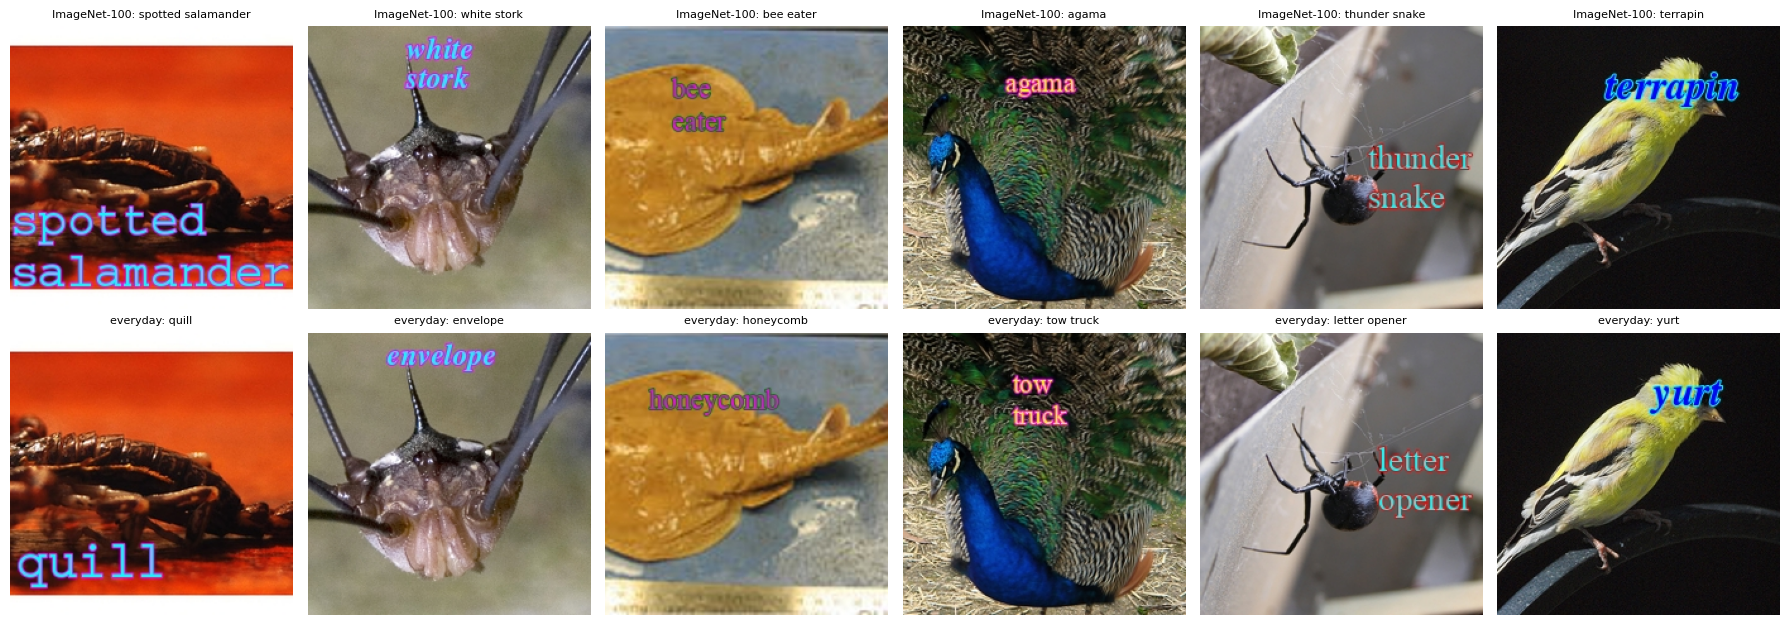

In [9]:
# 6) Example pairs for the report: same image and style, ImageNet-100 word (top) vs everyday word (bottom)
import random, matplotlib.pyplot as plt
from PIL import Image
os.chdir(f"{BASE}/Defense-Prefix"); sys.path.insert(0, os.getcwd())
import torch, make_train_attacks as mta
d = torch.load(f"{OUT}/train_attacks_vocab.pt", map_location="cpu", weights_only=False)
idx = [i for i, (a, b) in enumerate(zip(d["word_ctrl"], d["word_vocab"])) if a != b]
parts = sorted(x for x in os.listdir(SRC) if x.startswith("train.X"))
def find(rel):
    for p in parts:
        f = os.path.join(SRC, p, rel)
        if os.path.exists(f): return f
fig, axs = plt.subplots(2, 6, figsize=(18, 6.4))
for j, i in enumerate(random.Random(0).sample(idx, 6)):
    font, fill, stroke = d["style"][i]
    base = mta.gen._transform(Image.open(find(d["relpaths"][i])))
    for row, w in ((0, d["word_ctrl"][i]), (1, d["word_vocab"][i])):
        axs[row, j].imshow(mta.render(base, w, d["seeds"][i], os.path.join(mta.FONT_DIR, font), fill, stroke))
        axs[row, j].axis("off")
        axs[row, j].set_title(("ImageNet-100: " if row == 0 else "everyday: ") + w, fontsize=8)
plt.tight_layout(); plt.savefig(f"{W}/train_attack_examples_vocab.png", dpi=150, bbox_inches="tight"); plt.show()